In [9]:
import os
import zipfile

# 1. Configurer les variables d'environnement Kaggle directement
os.environ['KAGGLE_USERNAME'] = "mayssaz123"
# Remplacez "VOTRE_CLE_SECRETE" par la clé qui se trouve dans votre fichier kaggle.json téléchargé
os.environ['KAGGLE_KEY'] = "b4af0d54b11ed5bf5949d835d9c76c67"

# 2. Installer kaggle si ce n'est pas fait
!pip install -q kaggle

# 3. Créer le dossier cible
os.makedirs("data/aptos", exist_ok=True)

# 4. Lancer le téléchargement
print("🔄 Téléchargement du dataset APTOS 2019...")
!kaggle competitions download -c aptos2019-blindness-detection -p data/

# 5. Extraire le fichier ZIP
print("📦 Extraction en cours...")
for file in os.listdir("data/"):
    if file.endswith(".zip"):
        zip_path = os.path.join("data/", file)
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall("data/aptos")
        print("✅ Extraction réussie dans 'data/aptos' !")
        break

# 6. Vérification finale
print("\n📁 Fichiers dans 'data/aptos' :")
print(os.listdir("data/aptos"))

🔄 Téléchargement du dataset APTOS 2019...
100% 9.51G/9.51G [04:02<00:00, 42.2MB/s]

📦 Extraction en cours...
✅ Extraction réussie dans 'data/aptos' !

📁 Fichiers dans 'data/aptos' :
['sample_submission.csv', 'test.csv', 'train.csv', 'test_images', 'train_images']


In [10]:
import os
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

# === Définition du chemin correct pour Colab ===
DATA_DIR = "data/aptos"

# === Load train.csv ===
df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

# Simplify to binary: 0 = normal, 1 = retinopathy
df["label"] = df["diagnosis"].apply(lambda x: 0 if x == 0 else 1)

print(df.head())


# === Custom Dataset ===
class RetinoDataset(Dataset):

  def __init__(self, csv_file, img_dir, transform=None):
    self.data = pd.read_csv(csv_file)
    self.data["label"] = self.data["diagnosis"].apply(
        lambda x: 0 if x == 0 else 1
    )
    self.img_dir = img_dir
    self.transform = transform

  def __len__(self):
    return len(self.data)

  def __getitem__(self, idx):
    img_name = str(self.data.iloc[idx, 0]) + ".png"  # id_code + extension
    img_path = os.path.join(self.img_dir, img_name)
    image = Image.open(img_path).convert("RGB")
    label = int(self.data.iloc[idx]["label"])

    if self.transform:
      image = self.transform(image)

    return image, label


# === Transforms  ===
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # match ResNet input
    transforms.ToTensor(),
])

# === Create dataset and dataloader ===
train_dataset = RetinoDataset(
    os.path.join(DATA_DIR, "train.csv"),
    os.path.join(DATA_DIR, "train_images"),
    transform=transform,
)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Example: fetch a batch
images, labels = next(iter(train_loader))
print(images.shape, labels[:10])

        id_code  diagnosis  label
0  000c1434d8d7          2      1
1  001639a390f0          4      1
2  0024cdab0c1e          1      1
3  002c21358ce6          0      0
4  005b95c28852          0      0
torch.Size([32, 3, 224, 224]) tensor([1, 0, 0, 0, 1, 0, 1, 0, 0, 1])


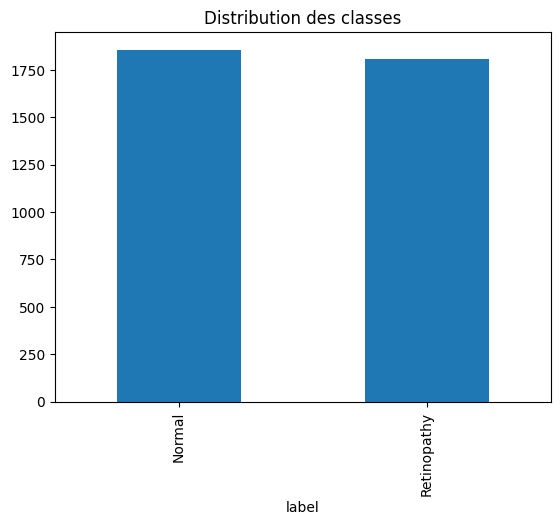

In [11]:
import matplotlib.pyplot as plt

df['label'].value_counts().plot(kind='bar')
plt.title('Distribution des classes')
plt.xticks([0,1], ['Normal','Retinopathy'])
plt.show()

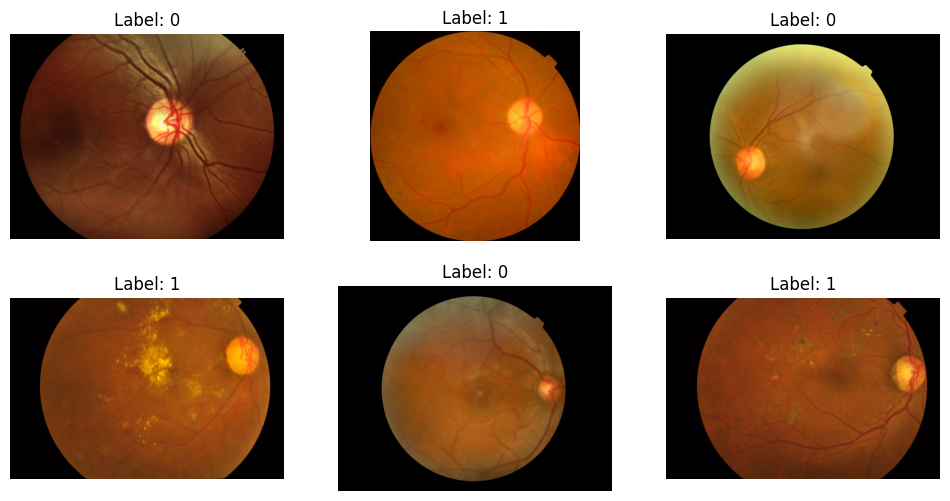

In [12]:
import matplotlib.pyplot as plt
import os
from PIL import Image

# Définition du chemin correct
DATA_DIR = "data/aptos"

# Sélection de 6 images aléatoires depuis votre DataFrame 'df'
sample_images = df.sample(6)

plt.figure(figsize=(12, 6))
for i, (_, row) in enumerate(sample_images.iterrows()):
  # Utilisation du chemin correct vers train_images
  img_path = os.path.join(DATA_DIR, "train_images", f"{row['id_code']}.png")
  img = Image.open(img_path)

  plt.subplot(2, 3, i + 1)
  plt.imshow(img)
  plt.title(f"Label: {row['label']}")
  plt.axis("off")

plt.show()

In [13]:
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

In [14]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import models, transforms
import pandas as pd
from PIL import Image
import os
import pickle
import matplotlib.pyplot as plt
import numpy as np
import random

# =============================================================================
# 1. Reproducibility
# =============================================================================

def set_seed(seed):
    """Sets the seed for reproducibility of results."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        # Warning: may slow down training
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# =============================================================================
# 2. Early Stopping Class
# =============================================================================

class EarlyStopping:
    """Stops training if validation loss doesn't improve after
    a given number of epochs (patience)."""
    def __init__(self, patience=3, delta=0, save_path="best_model.pth", verbose=True):
        self.patience = patience
        self.delta = delta # Minimum change to be considered an improvement
        self.save_path = save_path
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = float('inf')

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            # Performance did not improve
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            # Performance improved
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        """Saves model when validation loss decreases."""
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model...')
        torch.save(model.state_dict(), self.save_path)
        self.val_loss_min = val_loss

# =============================================================================
# 3. Custom Dataset Class
# =============================================================================

class RetinoDataset(torch.utils.data.Dataset):
    """Custom Dataset for loading retinopathy images."""
    def __init__(self, csv_file, img_dir, transform=None):
        self.data = pd.read_csv(csv_file)
        # Binary: 0 = healthy, 1 = diseased
        self.data["label"] = self.data["diagnosis"].apply(lambda x: 0 if x == 0 else 1)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_name = self.data.iloc[idx, 0] + ".png"
        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert("RGB")
        label = int(self.data.iloc[idx]["label"])
        if self.transform:
            image = self.transform(image)
        return image, label

# =============================================================================
# 4. Data Transforms
# =============================================================================

# Transforms for training data (with augmentation)
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

# Transforms for validation data (no augmentation)
val_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

# =============================================================================
# 5. Training and Validation Function
# =============================================================================

def train_one_phase(model, train_loader, val_loader, criterion, optimizer, scheduler, device, num_epochs, phase_name, early_stopper):
    """Trains the model for one phase with early stopping."""

    # We do NOT reset best_val_loss here,
    # as early_stopper manages it globally across phases.

    train_losses, val_losses, val_accuracies = [], [], []
    train_accuracies = []

    for epoch in range(num_epochs):
        # --- Training Loop ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backward pass and optimization
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Track stats
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

            if (i+1) % 10 == 0 or (i+1) == len(train_loader):
                print(f"[{phase_name}] Epoch [{epoch+1}/{num_epochs}], "
                      f"Batch [{i+1}/{len(train_loader)}], Loss: {loss.item():.4f}")

        train_loss = running_loss / len(train_loader)
        train_acc = correct_train / total_train

        # --- Validation Loop ---
        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()

                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_loss /= len(val_loader)
        val_acc = correct / total

        print(f"[{phase_name}] Epoch [{epoch+1}/{num_epochs}] "
              f"-> Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, "
              f"Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

        # Store history
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)
        train_accuracies.append(train_acc)

        scheduler.step()

        # Call Early Stopping
        # This will save the model if val_loss improves
        early_stopper(val_loss, model)
        if early_stopper.early_stop:
            print(f"[{phase_name}] Early Stopping at epoch {epoch+1}")
            break # Exit epoch loop

    return train_losses, val_losses, val_accuracies, train_accuracies

# =============================================================================
# 6. Plotting Function
# =============================================================================

def plot_training_history(history, phase1_len, phase2_len):
    """Generates and saves the loss and accuracy plots."""

    total_epochs = len(history['train_loss'])
    if total_epochs == 0:
        print("History is empty, cannot generate plots.")
        return

    epochs = range(1, total_epochs + 1)
    phase_sep = phase1_len

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Loss Plot
    ax1.plot(epochs, history['train_loss'], 'b-', marker='.', markersize=4, label='Train Loss', alpha=0.7)
    ax1.plot(epochs, history['val_loss'], 'r-', marker='.', markersize=4, label='Val Loss', alpha=0.7)
    if phase_sep > 0 and phase_sep < total_epochs:
        ax1.axvline(x=phase_sep + 0.5, color='gray', linestyle='--', alpha=0.7, label='Phase Transition')
    ax1.set_title('Training and Validation Loss')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Accuracy Plot
    ax2.plot(epochs, history['train_acc'], 'b-', marker='.', markersize=4, label='Train Accuracy', alpha=0.7)
    ax2.plot(epochs, history['val_acc'], 'r-', marker='.', markersize=4, label='Val Accuracy', alpha=0.7)
    if phase_sep > 0 and phase_sep < total_epochs:
        ax2.axvline(x=phase_sep + 0.5, color='gray', linestyle='--', alpha=0.7, label='Phase Transition')
    ax2.set_title('Training and Validation Accuracy')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # Annotations
    ylim_loss = ax1.get_ylim()
    ylim_acc = ax2.get_ylim()

    ax1.text(phase_sep/2, ylim_loss[1]*0.9, 'Phase 1\n(Head only)',
             ha='center', va='center', fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue"))
    if phase2_len > 0:
      ax1.text(phase_sep + phase2_len/2, ylim_loss[1]*0.9, 'Phase 2\n(Fine-tuning)',
               ha='center', va='center', fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgreen"))

    ax2.text(phase_sep/2, ylim_acc[0] + (ylim_acc[1]-ylim_acc[0])*0.1, 'Phase 1\n(Head only)',
             ha='center', va='center', fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue"))
    if phase2_len > 0:
      ax2.text(phase_sep + phase2_len/2, ylim_acc[0] + (ylim_acc[1]-ylim_acc[0])*0.1, 'Phase 2\n(Fine-tuning)',
               ha='center', va='center', fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgreen"))

    plt.tight_layout()

    # Saving plots
    os.makedirs("../models", exist_ok=True)
    plt.savefig("../models/training_history.png", dpi=300, bbox_inches='tight')
    plt.savefig("../models/training_history.pdf", bbox_inches='tight')
    plt.show()

    print("Plots saved to '../models/training_history.png' and '../models/training_history.pdf'")

In [16]:
import os
os.makedirs("models", exist_ok=True)

Utilisation du périphérique : cpu

===== Phase 1 : Entraînement de la tête seule =====
[head] Epoch [1/3], Batch [10/184], Loss: 0.4828
[head] Epoch [1/3], Batch [20/184], Loss: 0.3557
[head] Epoch [1/3], Batch [30/184], Loss: 0.2838
[head] Epoch [1/3], Batch [40/184], Loss: 0.2292
[head] Epoch [1/3], Batch [50/184], Loss: 0.1909
[head] Epoch [1/3], Batch [60/184], Loss: 0.1922
[head] Epoch [1/3], Batch [70/184], Loss: 0.3362
[head] Epoch [1/3], Batch [80/184], Loss: 0.2692
[head] Epoch [1/3], Batch [90/184], Loss: 0.2370
[head] Epoch [1/3], Batch [100/184], Loss: 0.4768
[head] Epoch [1/3], Batch [110/184], Loss: 0.2315
[head] Epoch [1/3], Batch [120/184], Loss: 0.1003
[head] Epoch [1/3], Batch [130/184], Loss: 0.2407
[head] Epoch [1/3], Batch [140/184], Loss: 0.3527
[head] Epoch [1/3], Batch [150/184], Loss: 0.1058
[head] Epoch [1/3], Batch [160/184], Loss: 0.2128
[head] Epoch [1/3], Batch [170/184], Loss: 0.1005
[head] Epoch [1/3], Batch [180/184], Loss: 0.2579
[head] Epoch [1/3], Ba

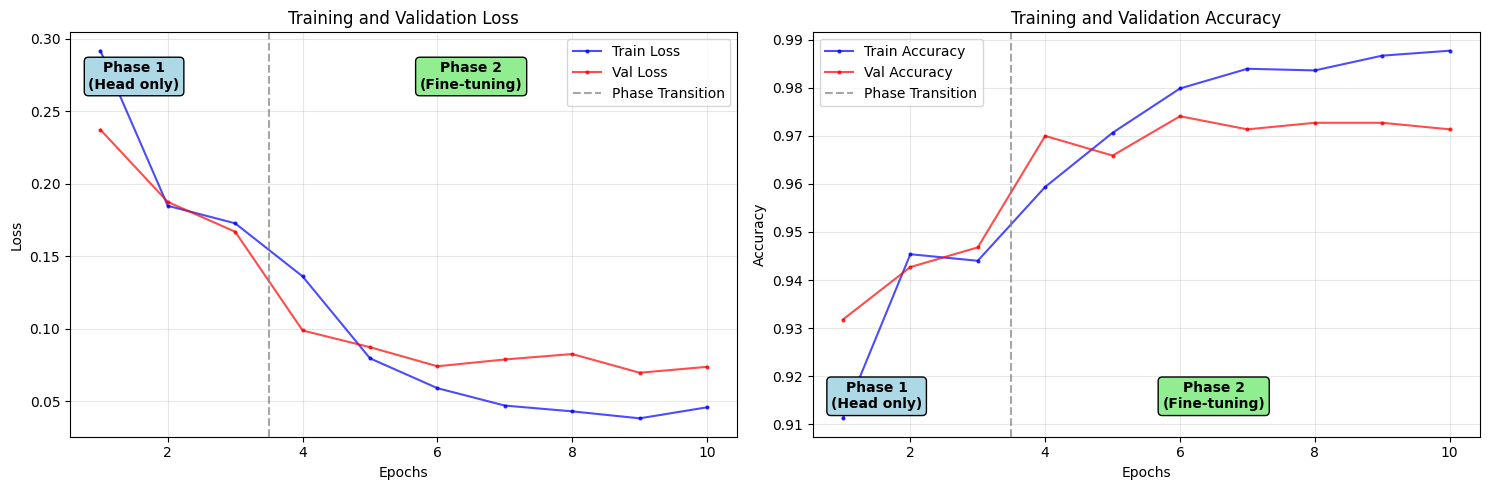

Plots saved to '../models/training_history.png' and '../models/training_history.pdf'

Entraînement terminé ! Historique et graphiques sauvegardés.
Le meilleur modèle est enregistré ici : models/resnet50_best_checkpoint.pth


In [17]:
if __name__ == "__main__":
  # --- Configuration ---
  set_seed(42)
  DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  NUM_WORKERS = 2  # 2 workers est optimal pour Colab standard
  BEST_MODEL_PATH = "models/resnet50_best_checkpoint.pth"
  print(f"Utilisation du périphérique : {DEVICE}")

  # --- Load Datasets (séparés pour éviter le conflit de transforms) ---
  csv_path = "data/aptos/train.csv"
  img_dir = "data/aptos/train_images"

  train_base_dataset = RetinoDataset(
      csv_path, img_dir, transform=train_transform
  )
  val_base_dataset = RetinoDataset(csv_path, img_dir, transform=val_transform)

  # Calcul des tailles de split (80% / 20%)
  total_size = len(train_base_dataset)
  train_size = int(0.8 * total_size)
  val_size = total_size - train_size

  # Génération d'indices fixes partagés pour la reproductibilité
  generator = torch.Generator().manual_seed(42)
  indices = torch.randperm(total_size, generator=generator).tolist()
  train_indices = indices[:train_size]
  val_indices = indices[train_size:]

  # Création des subsets
  train_dataset = torch.utils.data.Subset(train_base_dataset, train_indices)
  val_dataset = torch.utils.data.Subset(val_base_dataset, val_indices)

  # --- Dataloaders ---
  train_loader = DataLoader(
      train_dataset, batch_size=16, shuffle=True, num_workers=NUM_WORKERS
  )
  val_loader = DataLoader(
      val_dataset, batch_size=16, shuffle=False, num_workers=NUM_WORKERS
  )

  # --- Model Setup ---
  model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
  num_features = model.fc.in_features
  model.fc = nn.Linear(num_features, 2)  # Classification binaire (0 ou 1)
  model = model.to(DEVICE)

  # --- Early Stopping Setup ---
  early_stopper = EarlyStopping(
      patience=3,
      delta=0.001,  # Amélioration minimale
      save_path=BEST_MODEL_PATH,
      verbose=True,
  )

  # --- Phase 1: Train Head Only ---
  print("\n===== Phase 1 : Entraînement de la tête seule =====")

  for param in model.parameters():
    param.requires_grad = False
  for param in model.fc.parameters():
    param.requires_grad = True

  criterion = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
  scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

  t_losses1, v_losses1, v_accs1, t_accs1 = train_one_phase(
      model,
      train_loader,
      val_loader,
      criterion,
      optimizer,
      scheduler,
      DEVICE,
      num_epochs=3,
      phase_name="head",
      early_stopper=early_stopper,
  )

  # --- Phase 2: Fine-Tuning ---
  print("\nChargement du meilleur modèle avant la phase 2...")
  model.load_state_dict(torch.load(BEST_MODEL_PATH))

  # Dégel des couches 'layer4' et de la tête 'fc'
  for name, param in model.named_parameters():
    if "layer4" in name or "fc" in name:
      param.requires_grad = True
    else:
      param.requires_grad = False

  # Optimiseur avec un learning rate plus faible pour le fine-tuning
  optimizer = torch.optim.Adam(
      filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4
  )
  scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

  print("\n===== Phase 2 : Fine-tuning global =====")
  t_losses2, v_losses2, v_accs2, t_accs2 = train_one_phase(
      model,
      train_loader,
      val_loader,
      criterion,
      optimizer,
      scheduler,
      DEVICE,
      num_epochs=7,
      phase_name="finetune",
      early_stopper=early_stopper,
  )

  # --- Save History and Plot ---
  print("\n===== Génération des graphiques =====")
  history = {
      "train_loss": t_losses1 + t_losses2,
      "val_loss": v_losses1 + v_losses2,
      "train_acc": t_accs1 + t_accs2,
      "val_acc": v_accs1 + v_accs2,
  }

  os.makedirs("models", exist_ok=True)
  with open("models/history.pkl", "wb") as f:
    pickle.dump(history, f)

  # Génération des graphiques
  plot_training_history(
      history, phase1_len=len(t_losses1), phase2_len=len(t_losses2)
  )

  print(f"\nEntraînement terminé ! Historique et graphiques sauvegardés.")
  print(f"Le meilleur modèle est enregistré ici : {BEST_MODEL_PATH}")

Using device: cpu
Loading model weights from: models/resnet50_best_checkpoint.pth
Starting evaluation...

--- Evaluation Results ---
Validation Loss: 0.0697
Validation Accuracy: 0.9727 (713/733)

Classification Report:
              precision    recall  f1-score   support

 Healthy (0)     0.9643    0.9804    0.9723       358
Diseased (1)     0.9810    0.9653    0.9731       375

    accuracy                         0.9727       733
   macro avg     0.9727    0.9729    0.9727       733
weighted avg     0.9729    0.9727    0.9727       733

Generating confusion matrix...
Confusion matrix saved to 'models/confusion_matrix.png'


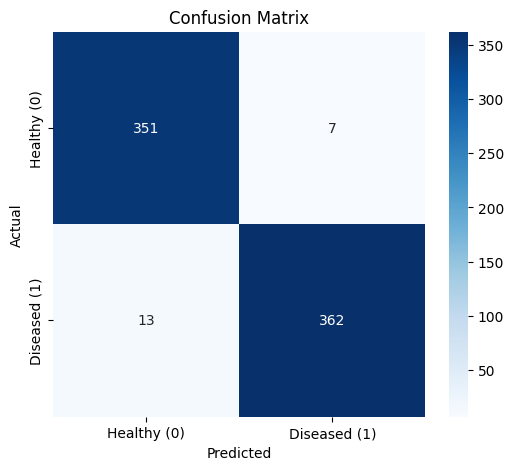

In [18]:
# =============================================================================
# 1. Imports
# =============================================================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import models, transforms

# =============================================================================
# 2. Custom Dataset Class
# =============================================================================


class RetinoDataset(torch.utils.data.Dataset):
  """Custom Dataset for loading retinopathy images."""

  def __init__(self, csv_file, img_dir, transform=None):
    self.data = pd.read_csv(csv_file)
    # Binary: 0 = healthy, 1 = diseased
    self.data["label"] = self.data["diagnosis"].apply(lambda x: 0 if x == 0 else 1)
    self.img_dir = img_dir
    self.transform = transform

  def __len__(self):
    return len(self.data)

  def __getitem__(self, idx):
    img_name = str(self.data.iloc[idx, 0]) + ".png"
    img_path = os.path.join(self.img_dir, img_name)
    image = Image.open(img_path).convert("RGB")
    label = int(self.data.iloc[idx]["label"])
    if self.transform:
      image = self.transform(image)
    return image, label


# =============================================================================
# 3. Validation Transforms
# =============================================================================
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# =============================================================================
# 4. Evaluation Function
# =============================================================================


def evaluate(model, data_loader, criterion, device):
  """Evaluates the model and prints detailed metrics."""
  model.eval()
  val_loss, correct, total = 0.0, 0, 0
  all_labels, all_preds = [], []

  with torch.no_grad():
    for images, labels in data_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      loss = criterion(outputs, labels)
      val_loss += loss.item()

      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

      all_labels.extend(labels.cpu().numpy())
      all_preds.extend(predicted.cpu().numpy())

  val_loss /= len(data_loader)
  val_acc = correct / total
  print(f"\n--- Evaluation Results ---")
  print(f"Validation Loss: {val_loss:.4f}")
  print(f"Validation Accuracy: {val_acc:.4f} ({correct}/{total})")

  # Classification report
  class_names = ["Healthy (0)", "Diseased (1)"]
  print("\nClassification Report:")
  print(
      classification_report(
          all_labels, all_preds, target_names=class_names, digits=4
      )
  )

  # Plot confusion matrix
  print("Generating confusion matrix...")
  cm = confusion_matrix(all_labels, all_preds)
  plt.figure(figsize=(6, 5))
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      xticklabels=class_names,
      yticklabels=class_names,
  )
  plt.xlabel("Predicted")
  plt.ylabel("Actual")
  plt.title("Confusion Matrix")

  # Save the matrix locally in 'models'
  os.makedirs("models", exist_ok=True)
  plt.savefig("models/confusion_matrix.png", dpi=300, bbox_inches="tight")
  print(f"Confusion matrix saved to 'models/confusion_matrix.png'")
  plt.show()


# =============================================================================
# 5. Main Execution
# =============================================================================
if __name__ == "__main__":

  # --- Configuration ---
  NUM_WORKERS = 2
  DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  BEST_MODEL_PATH = "models/resnet50_best_checkpoint.pth"
  print(f"Using device: {DEVICE}")

  # --- Load Dataset ---
  dataset = RetinoDataset(
      "data/aptos/train.csv", "data/aptos/train_images", transform=val_transform
  )

  train_size = int(0.8 * len(dataset))
  val_size = len(dataset) - train_size

  _, val_dataset = random_split(
      dataset,
      [train_size, val_size],
      generator=torch.Generator().manual_seed(42),
  )

  # --- Dataloader ---
  val_loader = DataLoader(
      val_dataset, batch_size=16, shuffle=False, num_workers=NUM_WORKERS
  )

  # --- Load Model Architecture ---
  model = models.resnet50(weights=None)
  num_features = model.fc.in_features
  model.fc = nn.Linear(num_features, 2)
  model = model.to(DEVICE)

  # --- Load Best Trained Weights ---
  print(f"Loading model weights from: {BEST_MODEL_PATH}")
  model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))

  criterion = nn.CrossEntropyLoss()

  # --- Evaluate ---
  print("Starting evaluation...")
  evaluate(model, val_loader, criterion, DEVICE)